<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/07_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7: How to Picture Neural Networks
## In your head and on paper

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

> Chapter 7 is a "thinking tools" chapter. The book contains **no new code listing** here. The cells below are my own demos that make each idea concrete, using the small *streetlight* network from Chapter 6, and they are marked as such.

---
## It's time to simplify

By the end of Chapter 6 the book has a 35-line, three-layer network that predicts whether it is safe to cross the street, and it hides more than 100 pages of concepts. Looking at every weight and every line of code is no longer practical, so Chapter 7 is about **compressing everything into a few ideas you can hold in your head**. These mental tools are what let you design new architectures, debug experiments, and move to new datasets.

The journey so far, from small ideas to big ones:
1. Machine learning in general → 2. a single neuron → 3. a *layer* (horizontal group of neurons) → 4. a *stack* of layers (vertical groups) → 5. learning as reducing error to 0 → 6. calculus to find how every weight should move.

All of that collapses into one sentence, introduced next.

---
## Correlation summarization

> **Correlation summarization:** a neural network seeks *direct and indirect correlation* between an input layer and an output layer, as defined by the input and output datasets.

Zooming in one level gives two complementary statements:

| Name | Statement |
|---|---|
| **Local** correlation summarization | Any set of weights optimises to correlate its **input layer** with whatever its **output layer** says it should be. |
| **Global** correlation summarization | What an earlier layer *should* be is found by taking what the later layer says it should be and multiplying by the weights in between. |

The second statement *is* **backpropagation**. The book's image: a giant game of telephone. The last layer says "I need to be higher", tells the layer before it "send me more signal", and so on back to the input. Once every layer knows what it should be, each weight matrix only has to do local learning.

**My demo: watching the telephone game.** We rebuild the Chapter 6 streetlight network and print how a delta travels backwards from `layer_2` to `layer_1` for one training example.

In [1]:
import numpy as np
np.random.seed(1)

def relu(x):        return (x > 0) * x
def relu2deriv(o):  return o > 0

streetlights = np.array([[1, 0, 1],
                         [0, 1, 1],
                         [0, 0, 1],
                         [1, 1, 1]])
walk_vs_stop = np.array([[1, 1, 0, 0]]).T

alpha, hidden_size = 0.2, 4
weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

# One example, before any training
layer_0 = streetlights[0:1]
layer_1 = relu(np.dot(layer_0, weights_0_1))
layer_2 = np.dot(layer_1, weights_1_2)

layer_2_delta = layer_2 - walk_vs_stop[0:1]                                   # "I'm off by this much"
layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)        # passed back through the weights

print("layer_1 (after relu)  :", (layer_1 + 0.0).round(3))
print("layer_2 prediction    :", layer_2.round(3), "  target:", walk_vs_stop[0])
print("layer_2_delta         :", layer_2_delta.round(3))
print("layer_1_delta         :", (layer_1_delta + 0.0).round(3))
print("hidden node switched off by relu? (1 = off):", (layer_1 == 0).astype(int))

layer_1 (after relu)  : [[0.    0.518 0.    0.   ]]
layer_2 prediction    : [[0.392]]   target: [1]
layer_2_delta         : [[-0.608]]
layer_1_delta         : [[ 0.   -0.46  0.    0.  ]]
hidden node switched off by relu? (1 = off): [[1 0 1 1]]


`layer_2_delta` is multiplied by `weights_1_2.T` (the weights *in between*) to tell `layer_1` what it should be. Nodes that relu switched off (value 0) contributed nothing to the error, so they receive a delta of 0. That is the whole of global correlation summarization in two lines. Now let's let it learn:

In [2]:
for iteration in range(60):
    layer_2_error = 0
    for i in range(len(streetlights)):
        layer_0 = streetlights[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        layer_2_error += np.sum((layer_2 - walk_vs_stop[i:i+1]) ** 2)
        layer_2_delta = (layer_2 - walk_vs_stop[i:i+1])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)

        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)

    if iteration % 10 == 9:
        print("Error:", layer_2_error)

Error: 0.6342311598444467
Error: 0.3583840767631751
Error: 0.08301831133032973
Error: 0.006467054957103672
Error: 0.0003292669000750735
Error: 1.5055622665134864e-05


The error falls toward 0 using only the telephone-game deltas and local weight updates, and the printed errors (0.634 → 0.358 → 0.083 → 0.0065 → 0.00033 → 1.5e-05) are identical to the book's Chapter 6 output.

---
## The previously overcomplicated visualization

Our earlier picture drew every node and every weight as a line. That was useful for learning how weights and layers fit together, but now it carries too much detail: because of the correlation summarization we no longer care about individual weight values, only that each matrix is learning correlation that generalises.

What actually exists in memory is simpler:
- **vectors**: the layers (`layer_0`, `layer_1`, ...), one per prediction, and
- **matrices**: the weights (`weights_0_1`, `weights_1_2`) connecting them.

---
## The simplified visualization

Neural networks are like **LEGO bricks**, and each brick is a vector or a matrix: a *strip* is a vector, a *box* is a matrix. Everything we developed (backpropagation, gradient descent, alpha, dropout, mini-batching) works no matter how you snap the bricks together. The only things you need to know are the **shapes**.

Below is a helper that draws such a picture for any list of layer sizes (my own function).

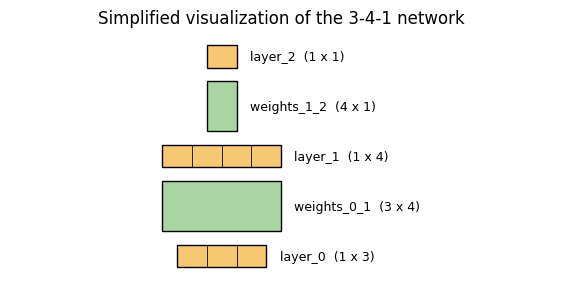

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def draw_lego(sizes, with_matrices=True, title=""):
    # sizes: nodes per layer, e.g. [3, 4, 1]. Layer 0 is drawn at the bottom, like in the book.
    cell, lh = 0.45, 0.4
    total_h = len(sizes) * (lh + 0.25) + (len(sizes) - 1) * (0.9 + 0.25 if with_matrices else 0)
    fig, ax = plt.subplots(figsize=(7, 0.55 * total_h + 0.8))
    y = 0
    for l, n in enumerate(sizes):
        w = n * cell
        ax.add_patch(Rectangle((-w / 2, y), w, lh, fc="#f7c873", ec="k"))
        for k in range(1, n):
            ax.plot([-w / 2 + k * cell] * 2, [y, y + lh], color="k", lw=.6)
        ax.text(w / 2 + .2, y + lh / 2, f"layer_{l}  (1 x {n})", va="center", fontsize=9)
        y += lh + 0.25
        if with_matrices and l < len(sizes) - 1:
            mw = sizes[l + 1] * cell
            ax.add_patch(Rectangle((-mw / 2, y), mw, 0.9, fc="#a8d5a2", ec="k"))
            ax.text(mw / 2 + .2, y + .45, f"weights_{l}_{l+1}  ({n} x {sizes[l+1]})", va="center", fontsize=9)
            y += 0.9 + 0.25
    ax.set_xlim(-3.2, 5); ax.set_ylim(-0.1, y); ax.axis("off"); ax.set_title(title)
    plt.show()

draw_lego([3, 4, 1], title="Simplified visualization of the 3-4-1 network")

**The big takeaway:** this picture still contains everything needed to build the network, namely the shape of every layer and every matrix.

---
## Simplifying even further

Notice that each matrix's shape is **fully determined by the two layers around it**: `weights_0_1` must connect 3 inputs to 4 hidden nodes, so it has to be **3 × 4**. Therefore you can drop the matrices from the picture and only draw layers, and, as a bonus, you can start thinking of the network as *one thing that adjusts weights to find correlation between `layer_0` and `layer_2`*.

The particular arrangement of layers and weights is called the network's **architecture**, and most of the rest of the book is about architectures.

> **Good architectures channel signal so that correlation is easy to discover. Great architectures also filter noise to help prevent overfitting.**

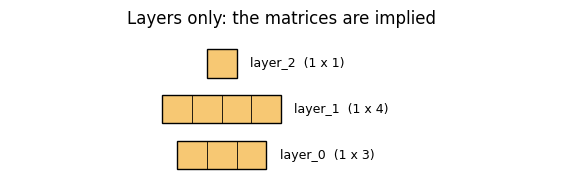

layers [3, 4, 1]       -> weight matrices [(3, 4), (4, 1)]
layers [784, 40, 10]   -> weight matrices [(784, 40), (40, 10)]
layers [3, 5, 5, 2]    -> weight matrices [(3, 5), (5, 5), (5, 2)]


In [4]:
draw_lego([3, 4, 1], with_matrices=False, title="Layers only: the matrices are implied")

def infer_weight_shapes(layer_sizes):
    # a matrix has (size of previous layer) rows and (size of next layer) columns
    return [(layer_sizes[i], layer_sizes[i + 1]) for i in range(len(layer_sizes) - 1)]

for sizes in ([3, 4, 1], [784, 40, 10], [3, 5, 5, 2]):
    print(f"layers {str(sizes):15s} -> weight matrices {infer_weight_shapes(sizes)}")

Check that the inferred shapes really make a working network (matrices built from the layer sizes alone, then a forward pass):

In [5]:
def random_forward(layer_sizes):
    x = np.ones((1, layer_sizes[0]))
    for (n_in, n_out) in infer_weight_shapes(layer_sizes):
        x = relu(x.dot(np.random.randn(n_in, n_out)))
    return x.shape

print(random_forward([3, 4, 1]), random_forward([784, 40, 10]), random_forward([3, 5, 5, 2]))

(1, 1) (1, 10) (1, 2)


---
## Let's see this network predict

Follow one streetlight datapoint, `layer_0 = [1, 0, 1]`, through the 3-4-1 network in three moves:

1. **Set** `layer_0` to the input values.
2. **Four weighted sums** of `layer_0` (vector-matrix multiplication with `weights_0_1`) fill the four slots of `layer_1`, then **relu** turns negative values into 0.
3. **One weighted sum** of `layer_1` (vector-matrix multiplication with `weights_1_2`) yields the prediction.

The weights below are *my own choice*, picked so that the numbers match the book's figure (`layer_1 = [.5, .2, 0, .9]`, prediction `.9`).

In [6]:
layer_0 = np.array([[1, 0, 1]])

weights_0_1 = np.array([[0.3, 0.1, -0.2,  0.4],
                        [0.1, 0.5,  0.2, -0.3],
                        [0.2, 0.1, -0.4,  0.5]])      # 3 x 4
weights_1_2 = np.array([[0.4], [0.8], [0.5], [0.6]])  # 4 x 1

step1 = layer_0.dot(weights_0_1)         # four weighted sums
layer_1 = relu(step1)                    # negative values become 0
layer_2 = layer_1.dot(weights_1_2)       # final weighted sum

print("weighted sums  :", step1.round(2), "<- the 3rd value is negative")
print("layer_1 (relu) :", (layer_1 + 0.0).round(2))
print("prediction     :", layer_2.round(2))

weighted sums  : [[ 0.5  0.2 -0.6  0.9]] <- the 3rd value is negative
layer_1 (relu) : [[0.5 0.2 0.  0.9]]
prediction     : [[0.9]]


---
## Visualizing using letters instead of pictures

The same thing can be written as simple algebra:

- a **matrix** is a **capital** letter. The book uses **W** for weights; a subscript tells them apart (W₀, W₁).
- a **vector** is a **lowercase** letter. The book uses **l** for layers (l₀, l₁, l₂).

These names are arbitrary. Pick whatever you can remember.

---
## Linking the variables

Putting two letters next to each other means **vector-matrix multiplication**, and functions like relu are written like the Python code:

| Algebra | Meaning |
|---|---|
| `l0 W0` | layer 0 times weight matrix 0 |
| `l1 = relu(l0 W0)` | multiply, then apply relu to build layer 1 |
| `l2 = l1 W1` | layer 1 times weight matrix 1 |
| `l2 = relu(l0 W0) W1` | the **entire forward pass in one expression** |

(The formula quietly assumes the shapes are compatible.)

---
## Everything side by side

The same forward propagation, seen four ways: diagram, algebra, vectorised Python, and plain loops.

one-liner : [0.9]
loops     : 0.9
identical : True


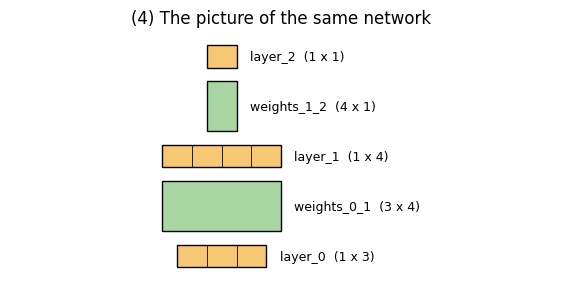

In [7]:
# (1) Algebra:  l2 = relu(l0 W0) W1
# (2) Book's one-liner:
pred_vectorized = relu(layer_0.dot(weights_0_1)).dot(weights_1_2)

# (3) Same thing with explicit Python loops (no NumPy dot)
hidden = []
for j in range(4):                                    # each hidden node = one weighted sum
    s = sum(layer_0[0][i] * weights_0_1[i][j] for i in range(3))
    hidden.append(max(0, s))                          # relu
pred_loops = sum(hidden[j] * weights_1_2[j][0] for j in range(4))

print("one-liner :", pred_vectorized.round(3).ravel())
print("loops     :", round(pred_loops, 3))
print("identical :", np.isclose(pred_vectorized[0][0], pred_loops))
draw_lego([3, 4, 1], title="(4) The picture of the same network")

---
## The importance of visualization tools

The following chapters keep rearranging vectors and matrices in new ways, and the author can only describe them if we share a **common language**. So don't move on until you can *see* forward propagation as pictures, as algebra, and as code, and translate between the three.

Different data has different kinds of signal and noise (images are not text), so different architectures suit different problems. The next chapters explore architectures that help the network find the correlation you want and ignore the noise.

---
## Summary

- **Correlation summarization**: a network finds (and sometimes invents) correlation between its input and output layers.
- **Local** = each weight matrix correlates its input with what its output layer wants; **global** = later layers tell earlier layers what to be (**backpropagation**).
- Draw networks as **vectors (strips) and matrices (boxes)**; matrix shapes follow from layer sizes.
- Three equivalent notations: picture, algebra (`l2 = relu(l0W0)W1`), code (`relu(layer_0.dot(weights_0_1)).dot(weights_1_2)`).
- **Architecture** = how layers and weights are arranged; good ones channel signal and filter noise.